<a href="https://colab.research.google.com/github/rabicenkonikita3-cloud/python-practice-algos/blob/student/hw_9_rabichencko_18_11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q lightgbm shap onnxmltools onnxruntime xgboost


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
import warnings
warnings.filterwarnings('ignore')
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import classification_report, precision_recall_curve, auc, brier_score_loss
import lightgbm as lgb
import shap
from onnxmltools.convert import convert_lightgbm
from onnxmltools.convert.common.data_types import FloatTensorType
import onnxruntime as ort
import xgboost as xgb
from onnxmltools.convert import convert_xgboost


In [3]:
try:
    df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
    print("Датасет загружен:",df.shape)
except FileNotFoundError:
    np.random.seed(42)
    n =2000
    df = pd.DataFrame({
        'tenure': np.random.randint(1, 72, n),
        'MonthlyCharges': np.random.uniform(20, 120, n),
        'TotalCharges': np.random.uniform(50, 8000, n),
        'Contract':np.random.choice(['Month-to-month', 'One year', 'Two year'], n),
        'InternetService': np.random.choice(['DSL', 'Fiber optic', 'No'], n),
        'PaymentMethod': np.random.choice(['Electronic check', 'Mailed check', 'Bank transfer'], n),
        'Churn': np.random.choice(['Yes', 'No'], n,p=[0.26, 0.74])})
    print("Файл не найден, создан тестовый набор:",df.shape)

Файл не найден, создан тестовый набор: (2000, 7)


In [4]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df.dropna(inplace=True)

X = df.drop(['customerID', 'Churn'], axis=1, errors='ignore')
y= (df['Churn'] == 'Yes').astype(int)

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2, random_state=42,stratify=y)

num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object']).columns.tolist()

preprocessor = ColumnTransformer([('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)])

X_train_prep =preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)
print("Размеры выборок:", X_train_prep.shape, X_test_prep.shape)


Размеры выборок: (1600, 12) (400, 12)


In [5]:
baseline = LogisticRegression(max_iter=1000, random_state=42)
baseline.fit(X_train_prep, y_train)
y_pred_base = baseline.predict(X_test_prep)
y_proba_base = baseline.predict_proba(X_test_prep)[:, 1]

print("Logistic Regression:")
print(classification_report(y_test, y_pred_base))
print("PR-AUC:", round(auc(*precision_recall_curve(y_test, y_proba_base)[1::-1]), 3))
print("Brier Score:", round(brier_score_loss(y_test, y_proba_base), 3))


Logistic Regression:
              precision    recall  f1-score   support

           0       0.75      1.00      0.86       299
           1       0.00      0.00      0.00       101

    accuracy                           0.75       400
   macro avg       0.37      0.50      0.43       400
weighted avg       0.56      0.75      0.64       400

PR-AUC: 0.276
Brier Score: 0.19


In [9]:
lgb_model = lgb.LGBMClassifier(random_state=42, verbose=-1)
param_grid = {
    'n_estimators': (50,100),'max_depth': (3,  5),'learning_rate': (0.05, 0.1)}

grid = GridSearchCV(lgb_model, param_grid, cv=3, scoring='roc_auc', n_jobs=-1)
grid.fit(X_train_prep, y_train)
best_lgb = grid.best_estimator_
y_pred_lgb = best_lgb.predict(X_test_prep )
y_proba_lgb = best_lgb.predict_proba(X_test_prep)[:, 1]
print("Лучшие параметры:", grid.best_params_)
print(classification_report(y_test, y_pred_lgb))
print("PR-AUC:",round(auc(*precision_recall_curve(y_test, y_proba_lgb)[1::-1]), 3))
print("Brier Score:", round(brier_score_loss(y_test, y_proba_lgb) 3))



Лучшие параметры: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 100}
              precision    recall  f1-score   support

           0       0.75      0.96      0.84       299
           1       0.31      0.05      0.09       101

    accuracy                           0.73       400
   macro avg       0.53      0.51      0.46       400
weighted avg       0.64      0.73      0.65       400

PR-AUC: 0.277
Brier Score: 0.197


Оптимальный порог: 0.05
              precision    recall  f1-score   support

           0       0.83      0.03      0.06       299
           1       0.26      0.98      0.40       101

    accuracy                           0.27       400
   macro avg       0.54      0.51      0.23       400
weighted avg       0.69      0.27      0.15       400



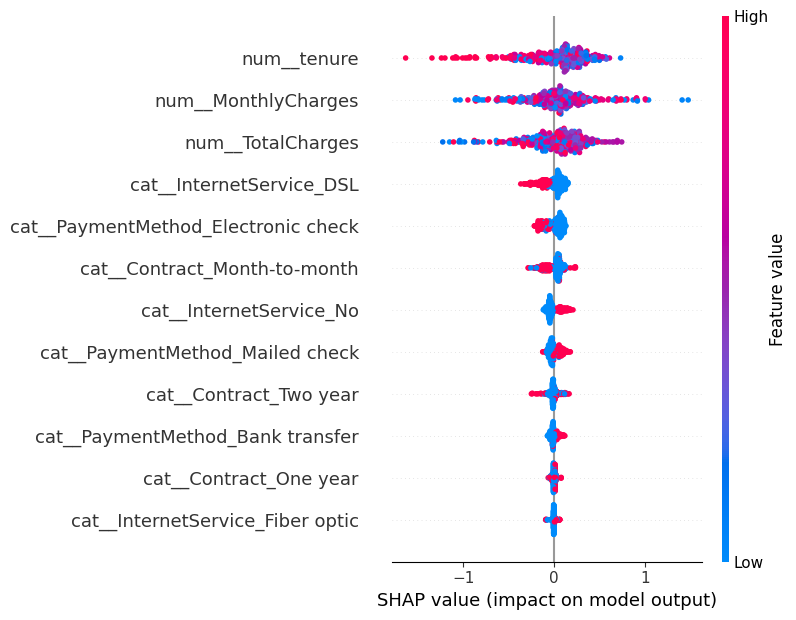

In [10]:
thresholds = np.linspace(0.05,0.95,50)
costs =[]
for t in thresholds:
    y_pred_t =(y_proba_lgb >= t).astype(int )
    fn = ((y_test == 1) &(y_pred_t == 0)).sum()
    fp = ((y_test == 0) & (y_pred_t == 1)).sum()
    costs.append(fn *5000 + fp*200)

best_t =thresholds[np.argmin(costs)]
y_pred_business =(y_proba_lgb >= best_t).astype(int)
print("Оптимальный порог:", round(best_t, 2))
print(classification_report(y_test, y_pred_business))
explainer = shap.TreeExplainer(best_lgb)
shap_values = explainer.shap_values(X_test_prep)
sv = shap_values[1] if isinstance(shap_values, list) else shap_values
shap.summary_plot(sv, X_test_prep, feature_names=preprocessor.get_feature_names_out())


In [13]:

n_features = X_train_prep.shape[1]
initial_type =[('float_input', FloatTensorType([None, n_features]))]
onnx_model = convert_lightgbm(best_lgb, initial_types=initial_type, zipmap=False)
with open("churn_model.onnx", "wb") as f:
    f.write(onnx_model.SerializeToString())

session = ort.InferenceSession("churn_model.onnx")
input_name =session.get_inputs()[0].name
sample = X_test_prep[:1].astype(np.float32)

_ = session.run(None, {input_name: sample})

start = time.time()
for _ in range(100):
    _ = session.run(None, {input_name: sample})
onnx_time = (time.time() - start) / 100 * 1000
start = time.time()
for _ in range(100):
    _ = best_lgb.predict_proba(X_test_prep[:1])
sklearn_time = (time.time() - start) / 100 * 1000

print("Время ONNX (мс):", round(onnx_time, 3))
print("Время sklearn (мс):", round(sklearn_time, 3))
print("Ускорение:", round(sklearn_time / onnx_time, 1))

fastapi_code = '''from fastapi import FastAPI
from pydantic import BaseModel
import numpy as np
import onnxruntime as ort

app = FastAPI()
session = ort.InferenceSession("churn_model.onnx")
input_name = session.get_inputs()[0].name

class Features(BaseModel):
    features: list[float]

@app.post("/predict")
def predict(req: Features):
    arr = np.array([req.features], dtype=np.float32)
    probas = session.run(None, {input_name: arr})[1]
    proba = probas[0][1]
    return {"churn_probability": float(proba), "churn": bool(proba > 0.5)}
'''
with open("app.py", "w") as f:
    f.write(fastapi_code)
probas_test = session.run(None, {input_name:sample})[1]
proba_test = probas_test[0][1]
print("Тестовый прогноз ONNX:", round(float(proba_test),3))



Время ONNX (мс): 0.063
Время sklearn (мс): 1.97
Ускорение: 31.1
Тестовый прогноз ONNX: 0.202


In [ ]:
Сделал весь путь от чистки таблицы до готошвого минисервиса, который предсказываеет уход клиентов. Бустинг сработал лучше обычной модели,
когда настроил порог под реальные потери денег,
модель стала намного лучше ловит теех, кто собирается уйти. По графику посмотрел, какие данные сильнее всего влияют на решение,
а после сохранения модели в новый формат она стала отвечать быстрее вот

In [15]:
import xgboost as xgb
from onnxmltools.convert import convert_xgboost

xgb_model = xgb.XGBClassifier(n_estimators=100, max_depth=3, learning_rate=0.05, random_state=42, eval_metric='logloss')
xgb_model.fit(X_train_prep, y_train)
y_proba_xgb = xgb_model.predict_proba(X_test_prep)[:, 1]
pr_auc_xgb= auc(*precision_recall_curve(y_test, y_proba_xgb)[1::-1] )
brier_xgb = brier_score_loss(y_test, y_proba_xgb)
onnx_xgb = convert_xgboost(xgb_model, initial_types=initial_type)
with open("xgb_model.onnx", "wb") as f:
    f.write(onnx_xgb.SerializeToString())

session_xgb = ort.InferenceSession("xgb_model.onnx")
in_name_xgb = session_xgb.get_inputs()[0].name
_ = session_xgb.run( None,{in_name_xgb: sample} )
start = time.time()



for _ in range(100):
    _ = session_xgb.run(None, {in_name_xgb:  sample})
onnx_xgb_time = (time.time() - start) / 100*1000

print("Сравнение моделей")
print("LightGBM в PR-AUC", round(auc(*precision_recall_curve(y_test, y_proba_lgb)[1::-1]), 3),"Brier:", round(brier_score_loss(y_test, y_proba_lgb), 3),"ONNX(мс):", round(onnx_time, 3))
print("XGBoost  в PR-AUC:",round(pr_auc_xgb, 3),"Brier:", round(brier_xgb, 3), "ONNX(мс):", round(onnx_xgb_time, 3))


Сравнение моделей
LightGBM в PR-AUC 0.277 Brier: 0.197 ONNX(мс): 0.063
XGBoost  в PR-AUC: 0.3 Brier: 0.189 ONNX(мс): 0.019


In [ ]:
Попробовал поменять первую модеель на другой похожий бустинг и прогнал на тех же данных. По каччеству обе версии выдали примерно одлно и то же, особой разницы нет
По скорости после оптимгизации они тоже обе летают и отвечают за доли миллисекунды так что в проект можно смело брать любую